# Job Postings — EDA & Feature Engineering

**Goal:** understand the dataset and prepare features for a salary prediction model.

Dataset columns: `posting_id`, `posted_on`, `title`, `seniority`, `city`, `country`, `remote`, `salary_min_usd`, `salary_max_usd`, `company_size`, `skills`.

> **Important modeling rule:** salary columns are targets, not input features. Do not include `salary_min_usd`, `salary_max_usd`, `salary_mid_usd`, or `salary_range_usd` among model predictors. They are used only to construct the target and for analysis.

The notebook is organized into:
1. Data audit and quality checks
2. Cleaning and salary-target construction
3. Univariate and bivariate EDA
4. Skill analysis
5. Feature engineering
6. Export clean/model-ready datasets

In [ ]:
import re
import warnings
import joblib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)
from sklearn.metrics import (
    mean_absolute_error,
    median_absolute_error,
    mean_squared_error,
    r2_score
)
catboost_available = CATBOOST_AVAILABLE


In [1]:
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
  
df_raw = pd.read_csv("data-job-postings.csv")

print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]}")
display(df_raw.head())

Rows: 3,500 | Columns: 11


,posting_id,posted_on,title,seniority,city,country,remote,salary_min_usd,salary_max_usd,company_size,skills
0,J70781,2023-01-01,Junior Data Analyst,junior,New York,US,remote,65000.0,86500.0,midmarket,looker|excel|statistics|tableau|sql
1,J72149,2023-01-01,Data Analyst,mid,Chicago,US,hybrid,76500.0,102000.0,scaleup,statistics|looker|excel|python|tableau
2,J72672,2023-01-01,Analytics Engineer,mid,London,GB,remote,NaN,NaN,midmarket,python|dbt|airflow
3,J73484,2023-01-01,Senior Machine Learning Engineer,senior,Bengaluru,IN,onsite,58500.0,78000.0,scaleup,python|aws|sql|pytorch
4,J70384,2023-01-02,Junior BI Developer,junior,San Francisco,US,remote,74500.0,99500.0,midmarket,modelling|power bi|sql|excel|dax


## 1. Data audit

In [2]:
print("Shape:", df_raw.shape)
print("\nDtypes:")
display(df_raw.dtypes.rename("dtype").to_frame())

print("\nMissing values:")
missing = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(2)
}).sort_values("missing_pct", ascending=False)
display(missing)

print("\nExact duplicate rows:", df_raw.duplicated().sum())
print("Duplicate posting_id values:", df_raw["posting_id"].duplicated().sum() if "posting_id" in df_raw else "n/a")

print("\nNumeric summary:")
display(df_raw.describe().T)

print("\nCategorical summary:")
display(df_raw.describe(include="object").T)

Shape: (3500, 11)

Dtypes:


,dtype
posting_id,object
posted_on,object
title,object
seniority,object
city,object
country,object
remote,object
salary_min_usd,float64
salary_max_usd,float64
company_size,object



Missing values:


,missing_count,missing_pct
salary_min_usd,762,21.77
salary_max_usd,762,21.77
posting_id,0,0.00
posted_on,0,0.00
title,0,0.00
seniority,0,0.00
city,0,0.00
country,0,0.00
remote,0,0.00
company_size,0,0.00



Exact duplicate rows: 0
Duplicate posting_id values: 0

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
salary_min_usd,2738.0,104106.281958,50769.146511,17000.0,66500.0,98000.0,133500.0,307000.0
salary_max_usd,2738.0,138806.975895,67697.145049,22500.0,89000.0,131000.0,178000.0,409000.0



Categorical summary:


,count,unique,top,freq
posting_id,3500,3500,J70781,1
posted_on,3500,966,2025-08-19,10
title,3500,40,Data Analyst,307
seniority,3500,5,mid,1170
city,3500,10,San Francisco,532
country,3500,7,US,1579
remote,3500,3,hybrid,1594
company_size,3500,4,enterprise,1035
skills,3500,2811,sql|python|statistics,8


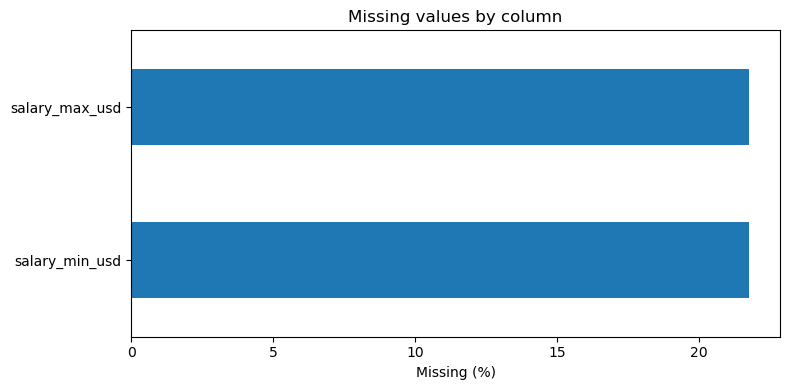

In [3]:
missing_nonzero = missing[missing["missing_count"] > 0].sort_values("missing_pct")
if not missing_nonzero.empty:
    ax = missing_nonzero["missing_pct"].plot(kind="barh", figsize=(8, 4))
    ax.set_title("Missing values by column")
    ax.set_xlabel("Missing (%)")
    ax.set_ylabel("")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

### Initial quality questions
- Are posting IDs unique?
- Are salary ranges logically valid (`min <= max`)?
- Do salary ranges have extreme values or inconsistent records?
- Is missing salary likely to be systematic across countries, seniority, or job titles?

In [4]:
for col in ["seniority", "country", "city", "remote", "company_size"]:
    print(f"\n{col}: {df_raw[col].nunique(dropna=False)} unique values")
    display(df_raw[col].value_counts(dropna=False).rename("count").to_frame().head(20))


seniority: 5 unique values


,count
seniority,
mid,1170
senior,984
junior,764
staff,339
lead,243



country: 7 unique values


,count
country,
US,1579
GB,436
IN,417
DE,333
CA,247
NL,245
BR,243



city: 10 unique values


,count
city,
San Francisco,532
New York,495
London,436
Bengaluru,417
Berlin,333
Chicago,299
Austin,253
Toronto,247
Amsterdam,245



remote: 3 unique values


,count
remote,
hybrid,1594
remote,1061
onsite,845



company_size: 4 unique values


,count
company_size,
enterprise,1035
scaleup,979
midmarket,825
startup,661


## 2. Cleaning and target construction

In [5]:
df = df_raw.copy()

text_cols = ["title", "seniority", "city", "country", "remote", "company_size", "skills"]
for col in text_cols:
    if col in df.columns:
        df[col] = df[col].astype("string").str.strip()

df["posted_on"] = pd.to_datetime(df["posted_on"], errors="coerce")

for col in ["salary_min_usd", "salary_max_usd"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["salary_range_invalid"] = (
    df["salary_min_usd"].notna()
    & df["salary_max_usd"].notna()
    & (df["salary_min_usd"] > df["salary_max_usd"])
)

print("Invalid dates:", df["posted_on"].isna().sum())
print("Rows with min salary > max salary:", df["salary_range_invalid"].sum())
print("Duplicate posting IDs:", df["posting_id"].duplicated().sum())

df = df.drop_duplicates(subset=["posting_id"], keep="first").copy()

invalid_salary_mask = (
    df["salary_min_usd"].notna()
    & df["salary_max_usd"].notna()
    & (df["salary_min_usd"] > df["salary_max_usd"])
)
df.loc[invalid_salary_mask, ["salary_min_usd", "salary_max_usd"]] = np.nan

df["salary_mid_usd"] = df[["salary_min_usd", "salary_max_usd"]].mean(axis=1)
df["salary_range_usd"] = df["salary_max_usd"] - df["salary_min_usd"]

salary_available = df["salary_mid_usd"].notna()
print(f"Salary-known rows: {salary_available.sum():,} ({salary_available.mean():.1%})")
print(f"Salary-missing rows: {(~salary_available).sum():,} ({(~salary_available).mean():.1%})")

display(df.loc[salary_available, [
    "title", "seniority", "country", "salary_min_usd",
    "salary_max_usd", "salary_mid_usd", "salary_range_usd"
]].head())

Invalid dates: 0
Rows with min salary > max salary: 0
Duplicate posting IDs: 0
Salary-known rows: 2,738 (78.2%)
Salary-missing rows: 762 (21.8%)


,title,seniority,country,salary_min_usd,salary_max_usd,salary_mid_usd,salary_range_usd
0,Junior Data Analyst,junior,US,65000.0,86500.0,75750.0,21500.0
1,Data Analyst,mid,US,76500.0,102000.0,89250.0,25500.0
3,Senior Machine Learning Engineer,senior,IN,58500.0,78000.0,68250.0,19500.0
4,Junior BI Developer,junior,US,74500.0,99500.0,87000.0,25000.0
5,Data Analyst,mid,US,76500.0,102000.0,89250.0,25500.0


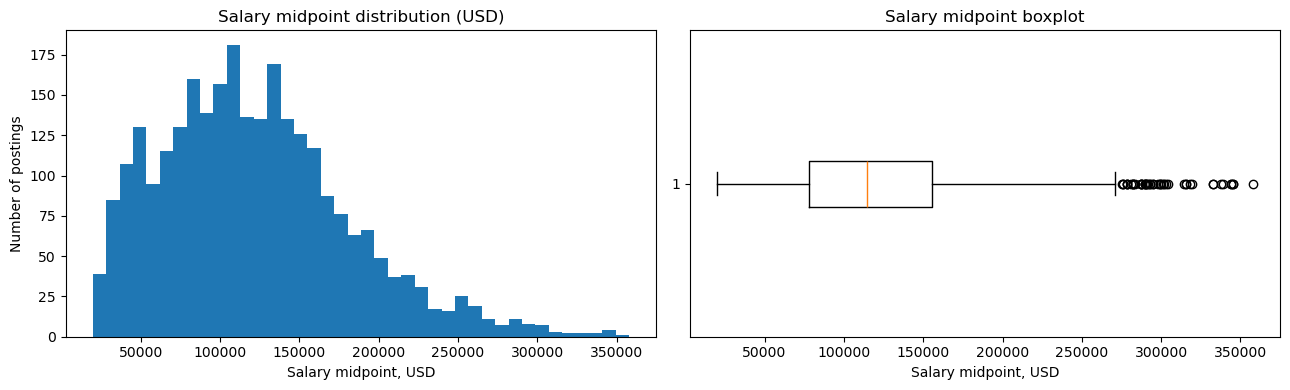

,salary_mid_usd
count,2738.000000
mean,121456.628926
std,59233.050102
min,19750.000000
1%,27250.000000
5%,37712.500000
25%,77750.000000
50%,114500.000000
75%,155750.000000
95%,230575.000000


In [6]:
salary = df.loc[df["salary_mid_usd"].notna(), "salary_mid_usd"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(salary, bins=40)
axes[0].set_title("Salary midpoint distribution (USD)")
axes[0].set_xlabel("Salary midpoint, USD")
axes[0].set_ylabel("Number of postings")

axes[1].boxplot(salary, vert=False)
axes[1].set_title("Salary midpoint boxplot")
axes[1].set_xlabel("Salary midpoint, USD")

plt.tight_layout()
plt.show()

display(salary.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).to_frame("salary_mid_usd"))

## 3. Univariate EDA

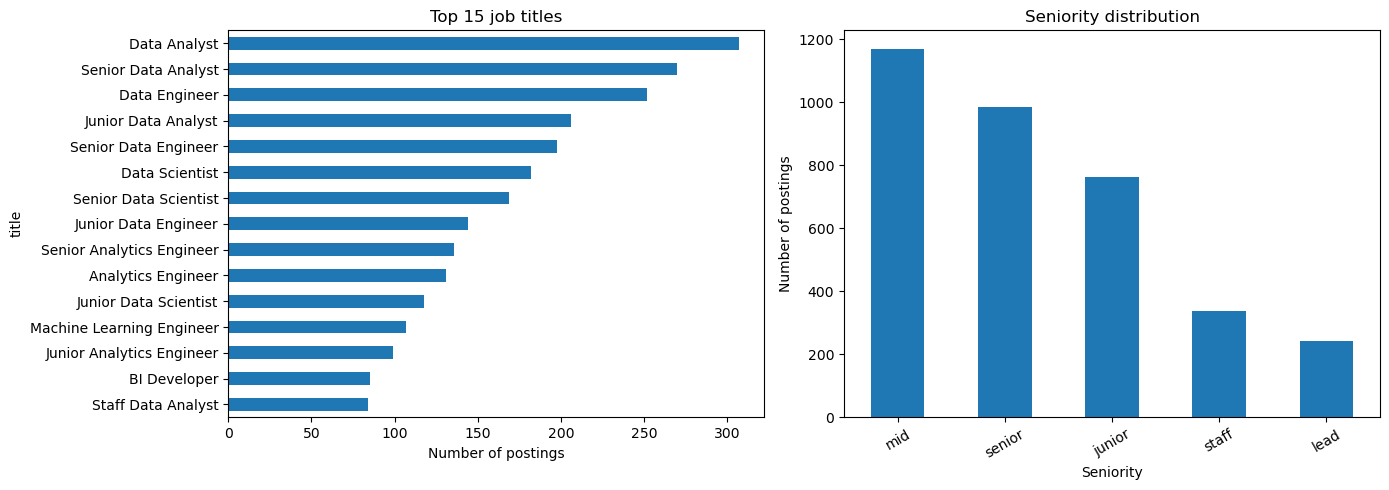

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df["title"].value_counts().head(15).sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Top 15 job titles")
axes[0].set_xlabel("Number of postings")

df["seniority"].value_counts().plot(kind="bar", ax=axes[1])
axes[1].set_title("Seniority distribution")
axes[1].set_xlabel("Seniority")
axes[1].set_ylabel("Number of postings")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

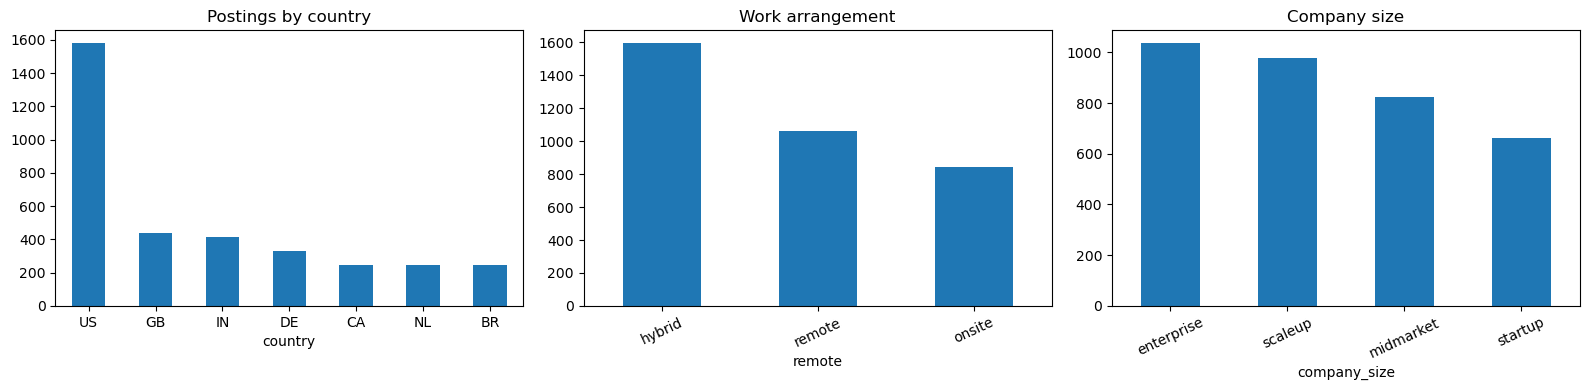

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

df["country"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_title("Postings by country")
axes[0].tick_params(axis="x", rotation=0)

df["remote"].value_counts().plot(kind="bar", ax=axes[1])
axes[1].set_title("Work arrangement")
axes[1].tick_params(axis="x", rotation=25)

df["company_size"].value_counts().plot(kind="bar", ax=axes[2])
axes[2].set_title("Company size")
axes[2].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

## 4. Salary analysis (bivariate EDA)

In [9]:
salary_df = df.loc[df["salary_mid_usd"].notna()].copy()

def grouped_salary_summary(group_col, min_n=10):
    out = salary_df.groupby(group_col, dropna=False).agg(
        postings=("salary_mid_usd", "size"),
        median_salary=("salary_mid_usd", "median"),
        mean_salary=("salary_mid_usd", "mean"),
        q25=("salary_mid_usd", lambda x: x.quantile(0.25)),
        q75=("salary_mid_usd", lambda x: x.quantile(0.75))
    )
    out = out[out["postings"] >= min_n].sort_values("median_salary", ascending=False)
    return out.round(0)

for col in ["seniority", "country", "remote", "company_size"]:
    print(f"\nSalary by {col}")
    display(grouped_salary_summary(col))


Salary by seniority


,postings,median_salary,mean_salary,q25,q75
seniority,,,,,
lead,189,187750.0,192886.0,151500.0,246250.0
staff,270,162250.0,167053.0,117688.0,216500.0
senior,815,135500.0,134495.0,96125.0,168000.0
mid,923,107000.0,105845.0,71750.0,136250.0
junior,541,80500.0,80741.0,56750.0,100500.0



Salary by country


,postings,median_salary,mean_salary,q25,q75
country,,,,,
US,1442,144625.0,153349.0,111500.0,186000.0
GB,294,108750.0,111370.0,80062.0,137625.0
NL,164,106125.0,109078.0,81000.0,132812.0
DE,222,96750.0,102965.0,76438.0,126375.0
CA,169,94000.0,100951.0,77000.0,121500.0
BR,166,50250.0,52330.0,39000.0,62500.0
IN,281,42750.0,43350.0,33250.0,51000.0



Salary by remote


,postings,median_salary,mean_salary,q25,q75
remote,,,,,
remote,829,117750.0,123936.0,78250.0,157500.0
onsite,656,114375.0,121094.0,77938.0,152500.0
hybrid,1253,112500.0,120006.0,77500.0,156250.0



Salary by company_size


,postings,median_salary,mean_salary,q25,q75
company_size,,,,,
scaleup,773,115750.0,122903.0,79250.0,159750.0
midmarket,652,114375.0,124092.0,79938.0,159750.0
startup,502,114000.0,118864.0,70625.0,152188.0
enterprise,811,113750.0,119565.0,77750.0,152250.0


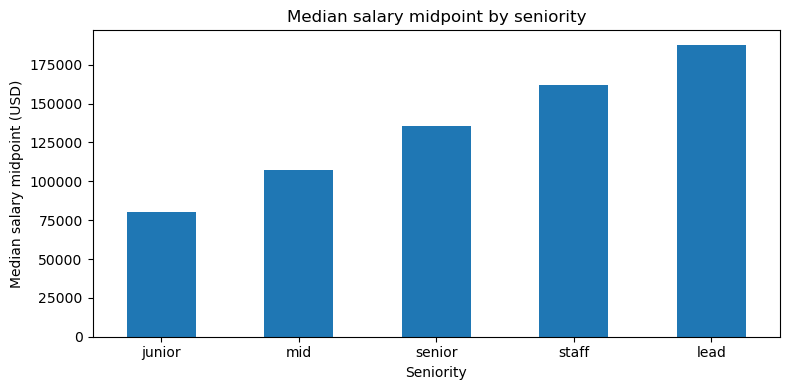

In [10]:
seniority_order = ["junior", "mid", "senior", "staff", "lead"]
med = salary_df.groupby("seniority")["salary_mid_usd"].median().reindex(seniority_order).dropna()

ax = med.plot(kind="bar", figsize=(8, 4))
ax.set_title("Median salary midpoint by seniority")
ax.set_ylabel("Median salary midpoint (USD)")
ax.set_xlabel("Seniority")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

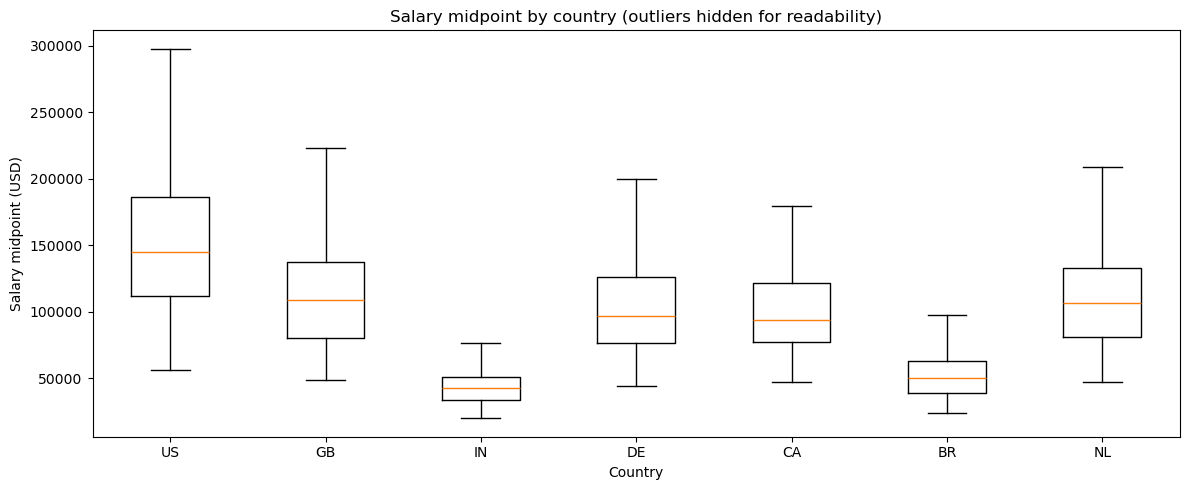

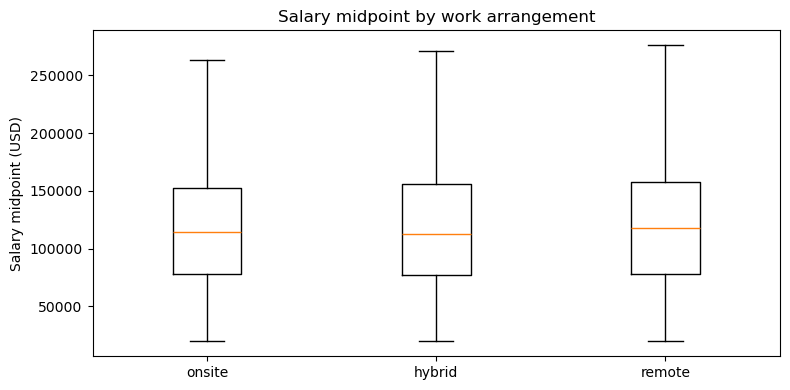

In [11]:
country_order = salary_df["country"].value_counts().index.tolist()
country_data = [salary_df.loc[salary_df["country"] == c, "salary_mid_usd"].dropna().values for c in country_order]
fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot(country_data, tick_labels=country_order, showfliers=False)
ax.set_title("Salary midpoint by country (outliers hidden for readability)")
ax.set_ylabel("Salary midpoint (USD)")
ax.set_xlabel("Country")
plt.tight_layout()
plt.show()

remote_order = ["onsite", "hybrid", "remote"]
remote_data = [salary_df.loc[salary_df["remote"] == r, "salary_mid_usd"].dropna().values for r in remote_order]
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(remote_data, tick_labels=remote_order, showfliers=False)
ax.set_title("Salary midpoint by work arrangement")
ax.set_ylabel("Salary midpoint (USD)")
plt.tight_layout()
plt.show()

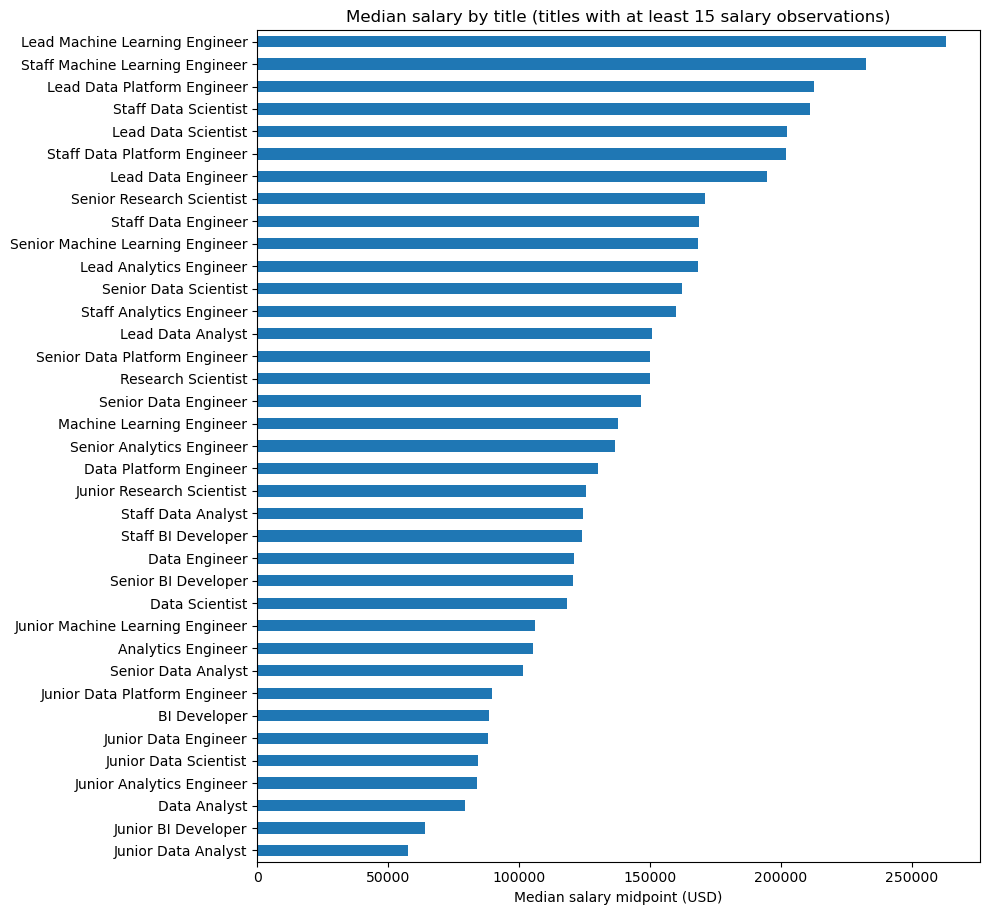

,postings,median_salary,mean_salary
title,,,
Lead Machine Learning Engineer,27,263000.0,255417.0
Staff Machine Learning Engineer,22,232500.0,229489.0
Lead Data Platform Engineer,15,212750.0,213600.0
Staff Data Scientist,37,211250.0,205635.0
Lead Data Scientist,25,202500.0,207910.0
Staff Data Platform Engineer,22,202000.0,198898.0
Lead Data Engineer,42,194625.0,202202.0
Senior Research Scientist,18,171250.0,174500.0
Staff Data Engineer,46,168750.0,175821.0


In [12]:
title_summary = salary_df.groupby("title").agg(
    postings=("salary_mid_usd", "size"),
    median_salary=("salary_mid_usd", "median"),
    mean_salary=("salary_mid_usd", "mean")
)
title_summary = title_summary[title_summary["postings"] >= 15].sort_values("median_salary", ascending=True)

ax = title_summary["median_salary"].plot(kind="barh", figsize=(10, max(5, len(title_summary) * 0.25)))
ax.set_title("Median salary by title (titles with at least 15 salary observations)")
ax.set_xlabel("Median salary midpoint (USD)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

display(title_summary.sort_values("median_salary", ascending=False).round(0))

## 5. Time analysis

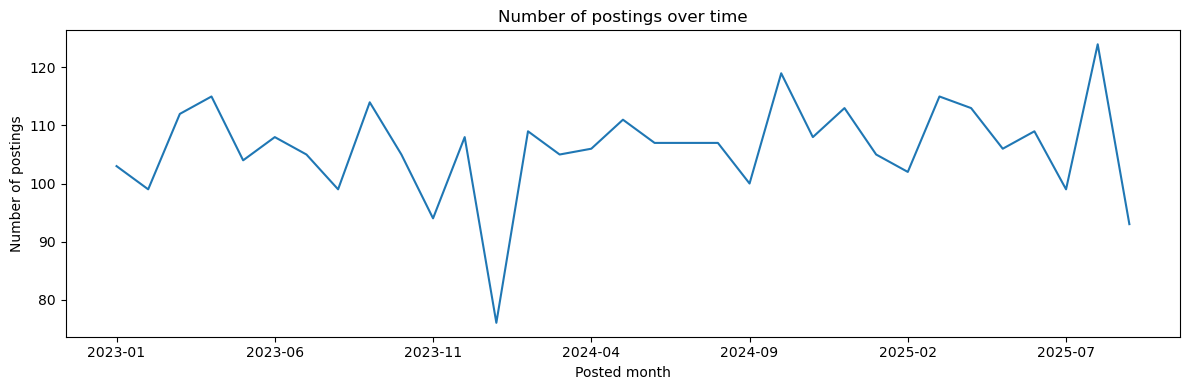

KeyError: 'posted_year'

In [13]:
df["posted_year"] = df["posted_on"].dt.year
df["posted_month"] = df["posted_on"].dt.month
df["posted_quarter"] = df["posted_on"].dt.quarter
df["posted_year_month"] = df["posted_on"].dt.to_period("M").astype("string")

postings_by_month = df.groupby("posted_year_month").size()
ax = postings_by_month.plot(figsize=(12, 4))
ax.set_title("Number of postings over time")
ax.set_xlabel("Posted month")
ax.set_ylabel("Number of postings")
plt.tight_layout()
plt.show()

salary_by_year = salary_df.groupby("posted_year")["salary_mid_usd"].median()
display(salary_by_year.rename("median_salary_mid_usd").to_frame())

## 6. Skills analysis

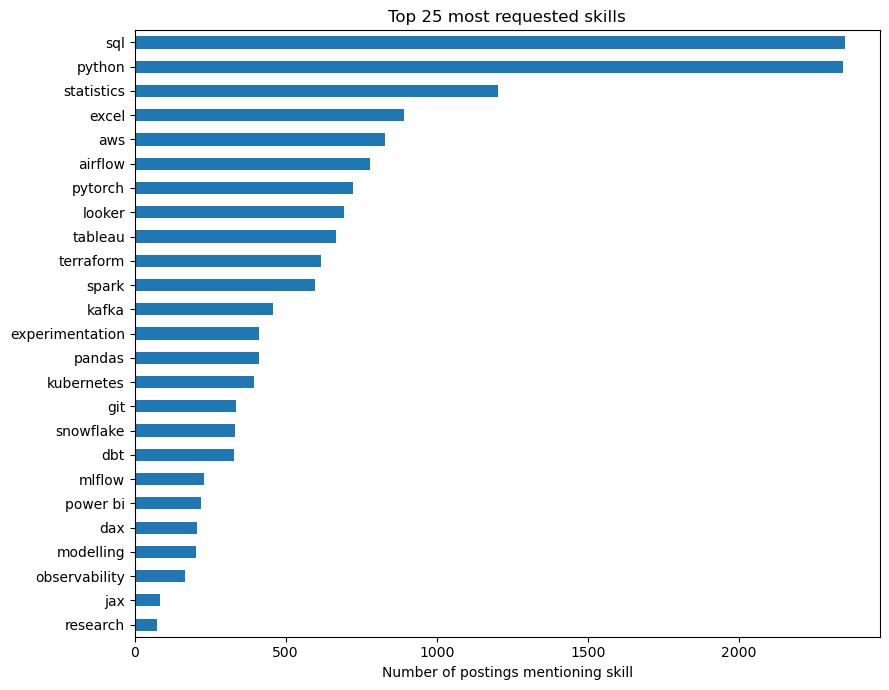

,skill,posting_count
2,sql,2350
5,python,2344
3,statistics,1204
0,excel,893
8,aws,830
6,airflow,778
9,pytorch,722
1,looker,694
4,tableau,666
15,terraform,617


In [14]:
def split_skills(value):
    if pd.isna(value):
        return []
    return sorted({
        s.strip().lower()
        for s in str(value).split("|")
        if s.strip()
    })

df["skills_list"] = df["skills"].apply(split_skills)
df["skills_count"] = df["skills_list"].str.len()

skill_counts = Counter(skill for skills in df["skills_list"] for skill in skills)
top_skills = pd.Series(skill_counts).sort_values(ascending=False).head(25).sort_values()

ax = top_skills.plot(kind="barh", figsize=(9, 7))
ax.set_title("Top 25 most requested skills")
ax.set_xlabel("Number of postings mentioning skill")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "skill": list(skill_counts.keys()),
    "posting_count": list(skill_counts.values())
}).sort_values("posting_count", ascending=False).head(30))

In [15]:
skill_salary_rows = []
for skill in skill_counts:
    mask = df["skills_list"].apply(lambda items: skill in items) & df["salary_mid_usd"].notna()
    vals = df.loc[mask, "salary_mid_usd"]
    if len(vals) >= 30:
        skill_salary_rows.append({
            "skill": skill,
            "postings_with_salary": len(vals),
            "median_salary_usd": vals.median(),
            "overall_median_usd": salary_df["salary_mid_usd"].median(),
            "median_difference_usd": vals.median() - salary_df["salary_mid_usd"].median()
        })

skill_salary = pd.DataFrame(skill_salary_rows).sort_values("median_difference_usd", ascending=False)
display(skill_salary.head(20).round(0))
display(skill_salary.tail(20).sort_values("median_difference_usd").round(0))

,skill,postings_with_salary,median_salary_usd,overall_median_usd,median_difference_usd
16,jax,68,165750.0,114500.0,51250.0
17,research,62,159750.0,114500.0,45250.0
18,mlflow,186,152000.0,114500.0,37500.0
13,kubernetes,308,150000.0,114500.0,35500.0
9,pytorch,564,144500.0,114500.0,30000.0
14,observability,128,138000.0,114500.0,23500.0
8,aws,654,135875.0,114500.0,21375.0
22,pandas,327,135750.0,114500.0,21250.0
21,experimentation,321,135250.0,114500.0,20750.0
19,kafka,354,132875.0,114500.0,18375.0


,skill,postings_with_salary,median_salary_usd,overall_median_usd,median_difference_usd
4,tableau,511,87000.0,114500.0,-27500.0
1,looker,530,87000.0,114500.0,-27500.0
0,excel,689,88000.0,114500.0,-26500.0
12,power bi,174,91500.0,114500.0,-23000.0
11,modelling,159,93000.0,114500.0,-21500.0
10,dax,159,94500.0,114500.0,-20000.0
3,statistics,926,104000.0,114500.0,-10500.0
2,sql,1842,111000.0,114500.0,-3500.0
24,snowflake,264,115375.0,114500.0,875.0
5,python,1838,117000.0,114500.0,2500.0


## 7. Feature engineering

In [16]:
df["posted_year"] = df["posted_on"].dt.year
df["posted_month"] = df["posted_on"].dt.month
df["posted_quarter"] = df["posted_on"].dt.quarter
df["posted_dayofweek"] = df["posted_on"].dt.dayofweek
df["posted_is_weekend"] = df["posted_dayofweek"].isin([5, 6]).astype("int8")

df["title_clean"] = df["title"].str.lower().str.strip()
df["title_word_count"] = df["title_clean"].str.split().str.len()

def title_family(title):
    t = str(title).lower()
    if "machine learning" in t or "ml engineer" in t:
        return "machine_learning"
    if "data scientist" in t:
        return "data_science"
    if "analytics engineer" in t:
        return "analytics_engineering"
    if "data engineer" in t:
        return "data_engineering"
    if "data analyst" in t or "business intelligence" in t or "bi analyst" in t:
        return "data_analytics"
    if "database" in t or "sql" in t:
        return "database_sql"
    if "research" in t:
        return "research"
    return "other_data_tech"

df["title_family"] = df["title"].apply(title_family)

df["skills_list"] = df["skills"].apply(split_skills)
df["skills_count"] = df["skills_list"].str.len()
df["skills_text"] = df["skills_list"].apply(lambda xs: " ".join(xs))

important_skills = [
    "sql", "python", "r", "excel", "tableau", "power bi", "looker",
    "statistics", "machine learning", "pytorch", "tensorflow",
    "airflow", "dbt", "spark", "aws", "azure", "gcp", "snowflake",
    "pandas", "numpy", "scikit-learn", "dax", "etl", "data modeling"
]
for skill in important_skills:
    col = "skill_" + re.sub(r"[^a-z0-9]+", "_", skill.lower()).strip("_")
    df[col] = df["skills_list"].apply(lambda xs: int(skill in xs)).astype("int8")

df["is_remote"] = (df["remote"].str.lower() == "remote").astype("int8")
df["is_hybrid"] = (df["remote"].str.lower() == "hybrid").astype("int8")
df["is_onsite"] = (df["remote"].str.lower() == "onsite").astype("int8")

df["salary_mid_usd"] = df[["salary_min_usd", "salary_max_usd"]].mean(axis=1)
df["salary_range_usd"] = df["salary_max_usd"] - df["salary_min_usd"]
df["salary_range_pct_of_mid"] = (
    df["salary_range_usd"] / df["salary_mid_usd"].replace(0, np.nan)
)

engineered_cols = [
    "title_family", "title_word_count", "skills_count",
    "posted_year", "posted_month", "posted_quarter", "posted_dayofweek",
    "posted_is_weekend", "is_remote", "is_hybrid", "is_onsite"
]
print("Engineered columns:")
display(df[engineered_cols].head())

Engineered columns:


,title_family,title_word_count,skills_count,posted_year,posted_month,posted_quarter,posted_dayofweek,posted_is_weekend,is_remote,is_hybrid,is_onsite
0,data_analytics,3,5,2023,1,1,6,1,1,0,0
1,data_analytics,2,5,2023,1,1,6,1,0,1,0
2,analytics_engineering,2,3,2023,1,1,6,1,1,0,0
3,machine_learning,4,4,2023,1,1,6,1,0,0,1
4,other_data_tech,3,5,2023,1,1,0,0,1,0,0


## 8. Build a model-ready dataset

In [20]:
model_df = df.loc[
    df["salary_min_usd"].notna()
    & df["salary_max_usd"].notna()
    & (df["salary_min_usd"] <= df["salary_max_usd"])
].copy()

model_df["target_salary_mid_usd"] = (
    model_df["salary_min_usd"] + model_df["salary_max_usd"]
) / 2
model_df["target_log_salary_mid_usd"] = np.log1p(model_df["target_salary_mid_usd"])

leakage_cols = [
    "salary_min_usd", "salary_max_usd", "salary_mid_usd",
    "salary_range_usd", "salary_range_pct_of_mid",
    "target_salary_mid_usd", "target_log_salary_mid_usd",
    "posting_id", "salary_range_invalid"
]
feature_cols = [c for c in model_df.columns if c not in leakage_cols]

print("Model rows:", len(model_df))
print("Feature count before encoding:", len(feature_cols))
print("Target median:", round(model_df["target_salary_mid_usd"].median(), 0), "USD")
print("Target mean:", round(model_df["target_salary_mid_usd"].mean(), 0), "USD")
display(model_df[feature_cols + ["target_salary_mid_usd"]].head())

Model rows: 2738
Feature count before encoding: 47
Target median: 114500.0 USD
Target mean: 121457.0 USD


,posted_on,title,seniority,city,country,remote,company_size,skills,posted_year,posted_month,posted_quarter,posted_year_month,skills_list,skills_count,posted_dayofweek,posted_is_weekend,title_clean,title_word_count,title_family,skills_text,skill_sql,skill_python,skill_r,skill_excel,skill_tableau,skill_power_bi,skill_looker,skill_statistics,skill_machine_learning,skill_pytorch,skill_tensorflow,skill_airflow,skill_dbt,skill_spark,skill_aws,skill_azure,skill_gcp,skill_snowflake,skill_pandas,skill_numpy,skill_scikit_learn,skill_dax,skill_etl,skill_data_modeling,is_remote,is_hybrid,is_onsite,target_salary_mid_usd
0,2023-01-01,Junior Data Analyst,junior,New York,US,remote,midmarket,looker|excel|statistics|tableau|sql,2023,1,1,2023-01,"[excel, looker, sql, statistics, tableau]",5,6,1,junior data analyst,3,data_analytics,excel looker sql statistics tableau,1,0,0,1,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,75750.0
1,2023-01-01,Data Analyst,mid,Chicago,US,hybrid,scaleup,statistics|looker|excel|python|tableau,2023,1,1,2023-01,"[excel, looker, python, statistics, tableau]",5,6,1,data analyst,2,data_analytics,excel looker python statistics tableau,0,1,0,1,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,89250.0
3,2023-01-01,Senior Machine Learning Engineer,senior,Bengaluru,IN,onsite,scaleup,python|aws|sql|pytorch,2023,1,1,2023-01,"[aws, python, pytorch, sql]",4,6,1,senior machine learning engineer,4,machine_learning,aws python pytorch sql,1,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,68250.0
4,2023-01-02,Junior BI Developer,junior,San Francisco,US,remote,midmarket,modelling|power bi|sql|excel|dax,2023,1,1,2023-01,"[dax, excel, modelling, power bi, sql]",5,0,0,junior bi developer,3,other_data_tech,dax excel modelling power bi sql,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,87000.0
5,2023-01-02,Data Analyst,mid,Austin,US,onsite,enterprise,excel|looker|python|tableau,2023,1,1,2023-01,"[excel, looker, python, tableau]",4,0,0,data analyst,2,data_analytics,excel looker python tableau,0,1,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,89250.0


In [21]:
df.to_csv("job_postings_engineered_all.csv", index=False)
model_df.to_csv("job_postings_model_ready.csv", index=False)

print("Saved:")
print("- job_postings_engineered_all.csv")
print("- job_postings_model_ready.csv")

Saved:
- job_postings_engineered_all.csv
- job_postings_model_ready.csv


## 9. Recommended next step: modeling

For a first benchmark:
- **Baseline:** predict the training-set median salary for every row.
- **Structured model:** CatBoostRegressor using categorical fields (`title`, `seniority`, `country`, `city`, `remote`, `company_size`, `title_family`) and numeric features (`skills_count`, date features, skill flags).
- **Text model:** TF-IDF on `title` and `skills_text`, combined with categorical/numeric features using a scikit-learn pipeline.
- **Metrics:** MAE in USD, median absolute error, and error by country/seniority.
- **Split:** use a time-based split if the goal is to predict future postings; otherwise use a train/test split with a fixed random seed.

Avoid random leakage from near-duplicate job postings. If multiple rows are generated from the same company or job family, consider grouped validation when those identifiers are available.

### Important limitation
This dataset has salary labels for only some postings, and the data appears to cover a limited set of countries and cities. A model trained on it should be described as estimating salaries in the dataset's market, not as a reliable salary oracle for every country.

In [19]:
model_df = df.loc[
    df["salary_min_usd"].notna()
    & df["salary_max_usd"].notna()
    & (df["salary_min_usd"] <= df["salary_max_usd"])
].copy()

model_df["target_salary_mid_usd"] = (
    model_df["salary_min_usd"] + model_df["salary_max_usd"]
) / 2

print("Model rows:", len(model_df))
print("Target median:", round(model_df["target_salary_mid_usd"].median(), 2))
print("Target mean:", round(model_df["target_salary_mid_usd"].mean(), 2))


# 8.1 FEATURE SELECTION

text_features = [
    "title_clean",
    "skills_text"
]

categorical_features = [
    "title_family",
    "seniority",
    "country",
    "city",
    "remote",
    "company_size"
]

numerical_features = [
    "skills_count",
    "posted_month",
    "posted_quarter",
    "title_word_count"
]

skill_features = [
    col for col in model_df.columns
    if col.startswith("skill_")
]

feature_cols = (
    text_features
    + categorical_features
    + numerical_features
    + skill_features
)

feature_cols = list(dict.fromkeys(feature_cols))

missing_features = [
    col for col in feature_cols
    if col not in model_df.columns
]

if missing_features:
    raise ValueError(
        f"Missing features: {missing_features}. "
        "Run Section 7 Feature Engineering first."
    )

X = model_df[feature_cols].copy()
y = model_df["target_salary_mid_usd"].copy()

for col in text_features:
    X[col] = X[col].fillna("").astype(str)

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())


# 8.2 DATA QUALITY CHECK

print("\nMissing values:")
display(X.isna().sum().sort_values(ascending=False))

print("\nDuplicate feature rows:", X.duplicated().sum())

print("\nFeature data types:")
display(X.dtypes)

print("\nTarget statistics:")
display(y.describe())


# 8.3 SAVE FINAL DATASET

final_df = X.copy()
final_df["target_salary_mid_usd"] = y

final_df.to_csv("salary_model_final.csv", index=False)

print("\nSaved: salary_model_final.csv")

Model rows: 2738
Target median: 114500.0
Target mean: 121456.63

Features shape: (2738, 36)
Target shape: (2738,)


,title_clean,skills_text,title_family,seniority,country,city,remote,company_size,skills_count,posted_month,posted_quarter,title_word_count,skill_sql,skill_python,skill_r,skill_excel,skill_tableau,skill_power_bi,skill_looker,skill_statistics,skill_machine_learning,skill_pytorch,skill_tensorflow,skill_airflow,skill_dbt,skill_spark,skill_aws,skill_azure,skill_gcp,skill_snowflake,skill_pandas,skill_numpy,skill_scikit_learn,skill_dax,skill_etl,skill_data_modeling
0,junior data analyst,excel looker sql statistics tableau,data_analytics,junior,US,New York,remote,midmarket,5,1,1,3,1,0,0,1,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,data analyst,excel looker python statistics tableau,data_analytics,mid,US,Chicago,hybrid,scaleup,5,1,1,2,0,1,0,1,1,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,senior machine learning engineer,aws python pytorch sql,machine_learning,senior,IN,Bengaluru,onsite,scaleup,4,1,1,4,1,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0
4,junior bi developer,dax excel modelling power bi sql,other_data_tech,junior,US,San Francisco,remote,midmarket,5,1,1,3,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
5,data analyst,excel looker python tableau,data_analytics,mid,US,Austin,onsite,enterprise,4,1,1,2,0,1,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0



Missing values:


title_clean               0
skills_text               0
skill_machine_learning    0
skill_pytorch             0
skill_tensorflow          0
skill_airflow             0
skill_dbt                 0
skill_spark               0
skill_aws                 0
skill_azure               0
skill_gcp                 0
skill_snowflake           0
skill_pandas              0
skill_numpy               0
skill_scikit_learn        0
skill_dax                 0
skill_etl                 0
skill_statistics          0
skill_looker              0
skill_power_bi            0
skills_count              0
title_family              0
seniority                 0
country                   0
city                      0
remote                    0
company_size              0
posted_month              0
skill_tableau             0
posted_quarter            0
title_word_count          0
skill_sql                 0
skill_python              0
skill_r                   0
skill_excel               0
skill_data_modeling 


Duplicate feature rows: 14

Feature data types:


...


Best model: CatBoost

ERROR ANALYSIS BY COUNTRY:


,postings,median_actual_salary,MAE
country,,,
IN,44,42500.0,2474.65
BR,35,46750.0,2978.31
DE,45,91500.0,3980.80
CA,34,98250.0,5061.96
GB,63,109000.0,5174.75
NL,35,105000.0,5500.34
US,292,146875.0,6790.52



TOP 15 IMPORTANT FEATURES:


,feature,importance
2,country,33.673653
1,seniority,32.796931
0,title_family,16.609161
3,city,6.160447
9,title_word_count,3.557700
13,skill_excel,2.128817
4,remote,0.671233
31,skill_dax,0.599930
23,skill_spark,0.586657
24,skill_aws,0.528435



Best model saved: best_salary_model.joblib
Model comparison saved.
Country error analysis saved.


In [20]:
# 9.1 CHRONOLOGICAL TRAIN-TEST SPLIT

sorted_df = model_df.sort_values(
    "posted_on",
    na_position="first"
).copy()

X_sorted = sorted_df[feature_cols].copy()
y_sorted = sorted_df["target_salary_mid_usd"].copy()

split_index = int(len(sorted_df) * 0.8)

split_date = sorted_df["posted_on"].iloc[split_index]

train_mask = (
    sorted_df["posted_on"].isna()
    | (sorted_df["posted_on"] < split_date)
)

test_mask = sorted_df["posted_on"] >= split_date

X_train = X_sorted.loc[train_mask].copy()
X_test = X_sorted.loc[test_mask].copy()

y_train = y_sorted.loc[train_mask].copy()
y_test = y_sorted.loc[test_mask].copy()

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print(
    "Train dates:",
    sorted_df.loc[train_mask, "posted_on"].min(),
    "-",
    sorted_df.loc[train_mask, "posted_on"].max()
)

print(
    "Test dates:",
    sorted_df.loc[test_mask, "posted_on"].min(),
    "-",
    sorted_df.loc[test_mask, "posted_on"].max()
)

cv = TimeSeriesSplit(n_splits=3)


# 9.2 BASELINE MODEL


baseline_model = DummyRegressor(
    strategy="median"
)

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

print("\nBaseline model trained.")


# 9.3 RIDGE REGRESSION - PREPROCESSING


numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])


preprocessor = ColumnTransformer(
    transformers=[

        (
            "title",
            TfidfVectorizer(
                max_features=3000,
                ngram_range=(1, 2),
                min_df=2,
                sublinear_tf=True
            ),
            "title_clean"
        ),

        (
            "skills_text",
            TfidfVectorizer(
                max_features=3000,
                ngram_range=(1, 2),
                min_df=2,
                sublinear_tf=True
            ),
            "skills_text"
        ),

        (
            "categorical",
            categorical_transformer,
            categorical_features
        ),

        (
            "numerical",
            numeric_transformer,
            numerical_features + skill_features
        )
    ]
)


ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge())
])


# 9.4 RIDGE REGRESSION - HYPERPARAMETER TUNING

ridge_params = {
    "regressor__alpha": [
        0.01,
        0.1,
        0.5,
        1.0,
        2.0,
        5.0,
        10.0,
        25.0,
        50.0,
        100.0
    ]
}

ridge_search = RandomizedSearchCV(
    estimator=ridge_pipeline,
    param_distributions=ridge_params,
    n_iter=10,
    scoring="neg_mean_absolute_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

ridge_search.fit(X_train, y_train)

ridge_model = ridge_search.best_estimator_

ridge_predictions = ridge_model.predict(X_test)

print("\nBest Ridge parameters:")
print(ridge_search.best_params_)

print("Best Ridge CV MAE:", -ridge_search.best_score_)


# 9.5 TREE-BASED MODELS - PREPROCESSING


tree_categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

tree_numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

tree_preprocessor = ColumnTransformer(
    transformers=[

        (
            "categorical",
            tree_categorical_transformer,
            categorical_features
        ),

        (
            "numerical",
            tree_numeric_transformer,
            numerical_features + skill_features
        )
    ],
    sparse_threshold=0
)


tree_features = (
    categorical_features
    + numerical_features
    + skill_features
)

X_tree_train = X_train[tree_features].copy()
X_tree_test = X_test[tree_features].copy()


# 9.6 DEFINE TREE-BASED MODELS AND PARAMETERS

models = {

    "Random Forest": {

        "model": RandomForestRegressor(
            random_state=42,
            n_jobs=1
        ),

        "params": {
            "model__n_estimators": [200, 400, 600],
            "model__max_depth": [None, 10, 20, 30],
            "model__min_samples_split": [2, 5, 10],
            "model__min_samples_leaf": [1, 2, 4],
            "model__max_features": [0.7, 1.0]
        }
    },

    "Extra Trees": {

        "model": ExtraTreesRegressor(
            random_state=42,
            n_jobs=1
        ),

        "params": {
            "model__n_estimators": [200, 400, 600],
            "model__max_depth": [None, 10, 20, 30],
            "model__min_samples_split": [2, 5, 10],
            "model__min_samples_leaf": [1, 2, 4],
            "model__max_features": [0.7, 1.0]
        }
    },

    "Gradient Boosting": {

        "model": GradientBoostingRegressor(
            random_state=42
        ),

        "params": {
            "model__n_estimators": [100, 200, 300, 500],
            "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
            "model__max_depth": [2, 3, 4],
            "model__min_samples_leaf": [2, 5, 10],
            "model__subsample": [0.7, 0.85, 1.0],
            "model__loss": ["huber", "absolute_error"]
        }
    },

    "Hist Gradient Boosting": {

        "model": HistGradientBoostingRegressor(
            random_state=42
        ),

        "params": {
            "model__max_iter": [100, 200, 300, 500],
            "model__learning_rate": [0.02, 0.05, 0.1],
            "model__max_leaf_nodes": [10, 15, 20, 31],
            "model__max_depth": [None, 5, 8, 10],
            "model__min_samples_leaf": [10, 20, 30],
            "model__l2_regularization": [0, 1, 5, 10],
            "model__loss": ["squared_error", "absolute_error"]
        }
    }
}


# 9.7 HYPERPARAMETER TUNING FOR TREE MODELS

trained_models = {}
tree_predictions = {}
tuning_results = []

for name, config in models.items():

    print("\nTraining:", name)

    pipeline = Pipeline([
        ("preprocessor", tree_preprocessor),
        ("model", config["model"])
    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=config["params"],
        n_iter=12,
        scoring="neg_mean_absolute_error",
        cv=cv,
        random_state=42,
        n_jobs=-1,
        verbose=1
    )

    search.fit(X_tree_train, y_train)

    trained_models[name] = search.best_estimator_

    tree_predictions[name] = search.best_estimator_.predict(
        X_tree_test
    )

    tuning_results.append({
        "Model": name,
        "Best CV MAE": -search.best_score_,
        "Best Parameters": search.best_params_
    })

    print("Best parameters:", search.best_params_)
    print("Best CV MAE:", -search.best_score_)


# 9.8 CATBOOST REGRESSION - OPTIONAL MODEL


catboost_available = CATBOOST_AVAILABLE

if not catboost_available:
    print("CatBoost is not installed. Skipping CatBoost model.")


if catboost_available:

    catboost_features = (
        categorical_features
        + numerical_features
        + skill_features
    )

    X_cb_train = X_train[catboost_features].copy()
    X_cb_test = X_test[catboost_features].copy()


    for col in categorical_features:

        X_cb_train[col] = (
            X_cb_train[col]
            .fillna("Unknown")
            .astype(str)
        )

        X_cb_test[col] = (
            X_cb_test[col]
            .fillna("Unknown")
            .astype(str)
        )



    for col in numerical_features + skill_features:

        median_value = X_cb_train[col].median()

        X_cb_train[col] = X_cb_train[col].fillna(median_value)
        X_cb_test[col] = X_cb_test[col].fillna(median_value)

    catboost_base = CatBoostRegressor(
        loss_function="MAE",
        eval_metric="MAE",
        random_seed=42,
        verbose=0,
        allow_writing_files=False,
        thread_count=1
    )

    catboost_params = {
        "iterations": [300, 500, 700, 1000],
        "depth": [4, 5, 6, 7, 8],
        "learning_rate": [0.02, 0.03, 0.05, 0.08, 0.1],
        "l2_leaf_reg": [3, 5, 7, 9],
        "random_strength": [0.5, 1, 2, 5]
    }

    catboost_search = RandomizedSearchCV(
        estimator=catboost_base,
        param_distributions=catboost_params,
        n_iter=12,
        scoring="neg_mean_absolute_error",
        cv=cv,
        random_state=42,
        n_jobs=1,
        verbose=1
    )

    catboost_search.fit(
        X_cb_train,
        y_train,
        cat_features=categorical_features
    )

    catboost_model = catboost_search.best_estimator_

    catboost_predictions = catboost_model.predict(
        X_cb_test
    )

    trained_models["CatBoost"] = catboost_model

    print("\nBest CatBoost parameters:")
    print(catboost_search.best_params_)

    print("Best CatBoost CV MAE:", -catboost_search.best_score_)

    tuning_results.append({
        "Model": "CatBoost",
        "Best CV MAE": -catboost_search.best_score_,
        "Best Parameters": catboost_search.best_params_
    })


# 9.9 MODEL EVALUATION

def evaluate_model(name, y_true, y_pred):

    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "MedianAE": median_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "R2": r2_score(y_true, y_pred)
    }


results = []


results.append(
    evaluate_model(
        "Baseline",
        y_test,
        baseline_predictions
    )
)


results.append(
    evaluate_model(
        "Ridge Regression",
        y_test,
        ridge_predictions
    )
)


for name, predictions in tree_predictions.items():

    results.append(
        evaluate_model(
            name,
            y_test,
            predictions
        )
    )


if catboost_available:

    results.append(
        evaluate_model(
            "CatBoost",
            y_test,
            catboost_predictions
        )
    )

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "MAE"
).reset_index(drop=True)

print("\nMODEL COMPARISON:")

display(results_df.round(2))


# 9.10 FINAL MODEL SELECTION

best_model_name = results_df.iloc[0]["Model"]

if best_model_name == "Baseline":

    best_model = baseline_model
    best_predictions = baseline_predictions

elif best_model_name == "Ridge Regression":

    best_model = ridge_model
    best_predictions = ridge_predictions

else:

    best_model = trained_models[best_model_name]

    if best_model_name == "CatBoost":
        best_predictions = catboost_predictions
    else:
        best_predictions = tree_predictions[best_model_name]

print("\nBest model:", best_model_name)

print(
    "Best test MAE:",
    results_df.iloc[0]["MAE"]
)


# 9.11 ERROR ANALYSIS BY COUNTRY

error_df = pd.DataFrame({

    "country": sorted_df.loc[
        X_test.index, "country"
    ].values,

    "actual_salary": y_test.values,

    "predicted_salary": best_predictions
})

error_df["absolute_error"] = (
    error_df["actual_salary"]
    - error_df["predicted_salary"]
).abs()

country_errors = (
    error_df.groupby("country")
    .agg(
        postings=("actual_salary", "count"),
        median_actual_salary=("actual_salary", "median"),
        MAE=("absolute_error", "mean")
    )
    .sort_values("MAE")
)

print("\nERROR ANALYSIS BY COUNTRY:")

display(country_errors.round(2))


# 9.12 FEATURE IMPORTANCE

if best_model_name == "CatBoost":

    feature_importance = pd.DataFrame({

        "feature": catboost_features,

        "importance": best_model.feature_importances_

    })

    feature_importance = feature_importance.sort_values(
        "importance",
        ascending=False
    )

    print("\nTOP 15 IMPORTANT FEATURES:")

    display(feature_importance.head(15))


elif best_model_name in [
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting"
]:

    fitted_model = best_model.named_steps["model"]

    transformed_names = (
        best_model.named_steps["preprocessor"]
        .get_feature_names_out()
    )

    feature_importance = pd.DataFrame({

        "feature": transformed_names,

        "importance": fitted_model.feature_importances_

    })

    feature_importance = feature_importance.sort_values(
        "importance",
        ascending=False
    )

    print("\nTOP 15 IMPORTANT FEATURES:")

    display(feature_importance.head(15))


# 9.13 SAVE BEST MODEL AND RESULTS

joblib.dump(
    best_model,
    "best_salary_model.joblib"
)

print("\nBest model saved: best_salary_model.joblib")


results_df.to_csv(
    "salary_model_comparison.csv",
    index=False
)


pd.DataFrame(tuning_results).to_csv(
    "hyperparameter_tuning_results.csv",
    index=False
)


country_errors.to_csv(
    "salary_error_by_country.csv"
)

print("\nAll results saved successfully.")

Training rows: 2188
Testing rows: 550
Train dates: 2023-01-01 00:00:00 - 2025-03-18 00:00:00
Test dates: 2025-03-19 00:00:00 - 2025-09-27 00:00:00

Baseline model trained.
Fitting 3 folds for each of 10 candidates, totalling 30 fits

Best Ridge parameters:
{'regressor__alpha': 1.0}
Best Ridge CV MAE: 11916.297184052584

Training: Random Forest
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters: {'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 1.0, 'model__max_depth': 20}
Best CV MAE: 8206.712211148504

Training: Extra Trees
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters: {'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 0.7, 'model__max_depth': 20}
Best CV MAE: 7678.07538222112

Training: Gradient Boosting
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters: {'model__subsample': 0.

,Model,MAE,MedianAE,RMSE,R2
0,CatBoost,5767.18,4477.42,7581.13,0.98
1,Hist Gradient Boosting,5904.81,4390.83,7816.77,0.98
2,Gradient Boosting,5980.62,4523.94,8041.14,0.98
3,Random Forest,6459.44,4604.34,8834.83,0.98
4,Extra Trees,6556.08,4710.00,9013.16,0.98
5,Ridge Regression,10516.73,7960.90,14731.89,0.94
6,Baseline,46235.45,38625.00,58773.75,-0.02



Best model: CatBoost
Best test MAE: 5767.179408685769

ERROR ANALYSIS BY COUNTRY:


,postings,median_actual_salary,MAE
country,,,
IN,44,42500.0,2552.40
BR,35,46750.0,2582.32
DE,45,91500.0,4083.00
CA,34,98250.0,5062.43
GB,63,109000.0,5439.59
NL,35,105000.0,5616.95
US,294,146875.0,7054.82



TOP 15 IMPORTANT FEATURES:


,feature,importance
1,seniority,32.914254
2,country,29.560426
3,city,11.587439
0,title_family,11.524829
13,skill_excel,5.131059
9,title_word_count,2.310832
16,skill_looker,1.547905
4,remote,0.791683
31,skill_dax,0.788367
23,skill_spark,0.772550



Best model saved: best_salary_model.joblib

All results saved successfully.


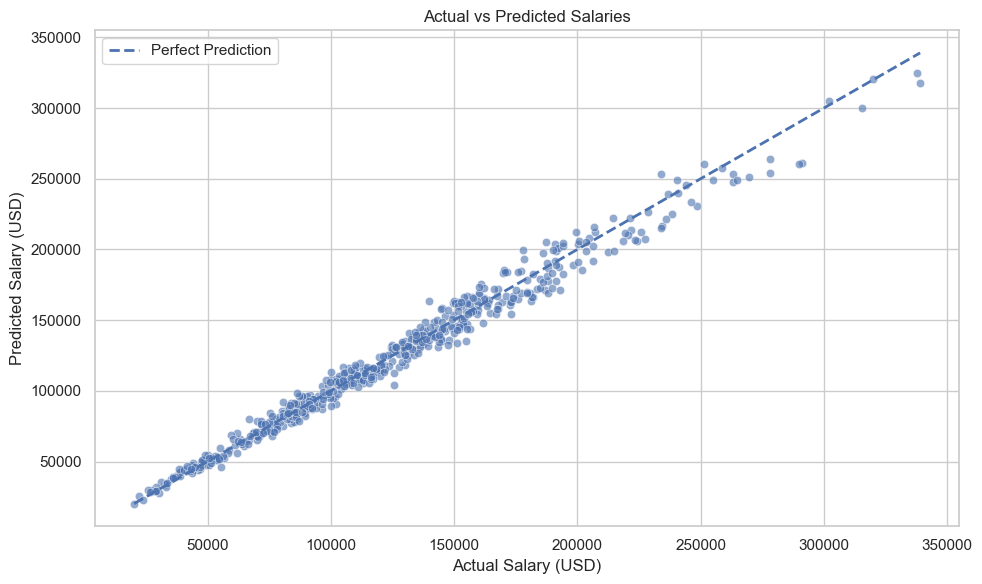

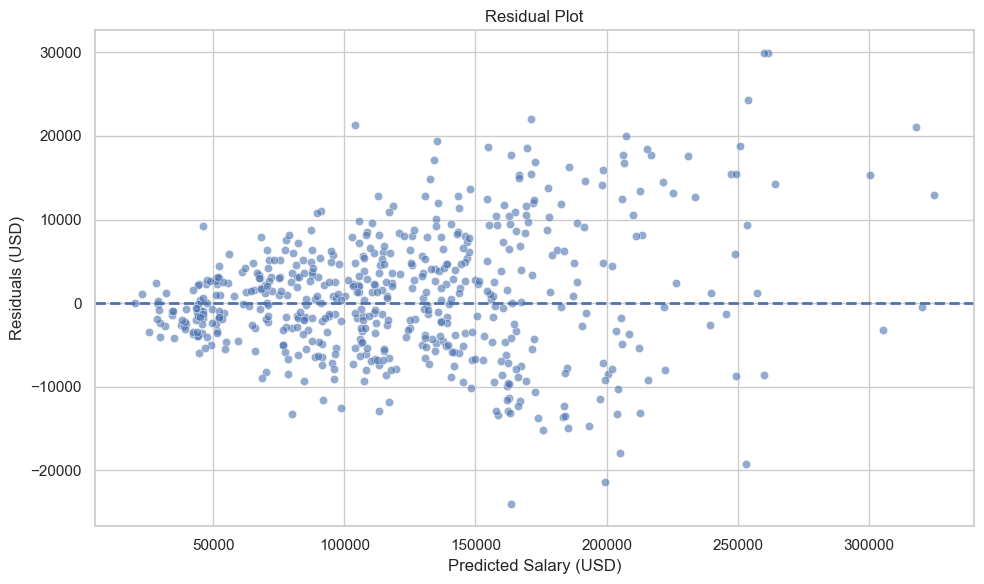

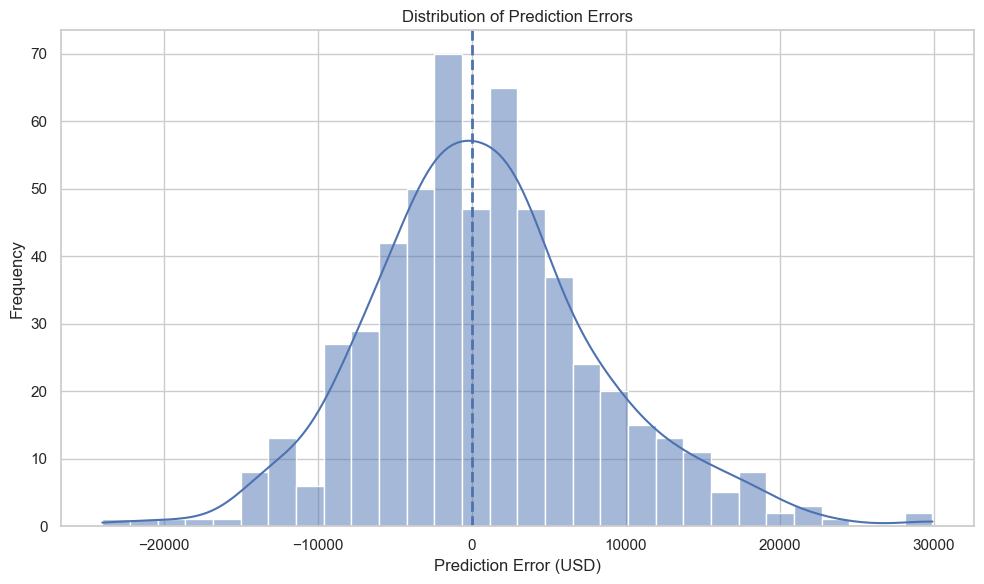

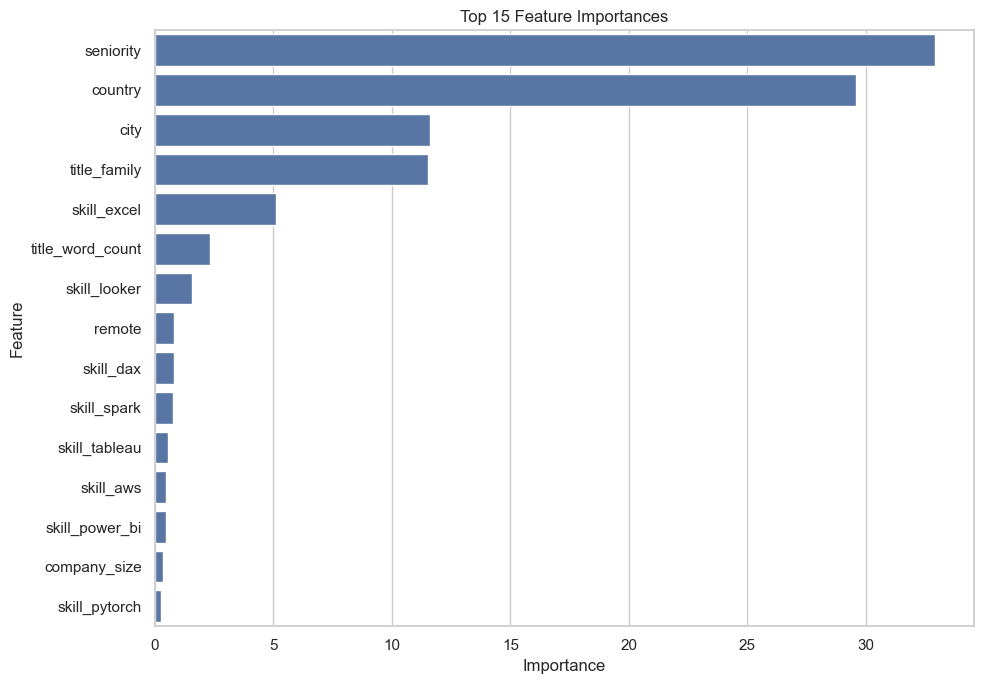

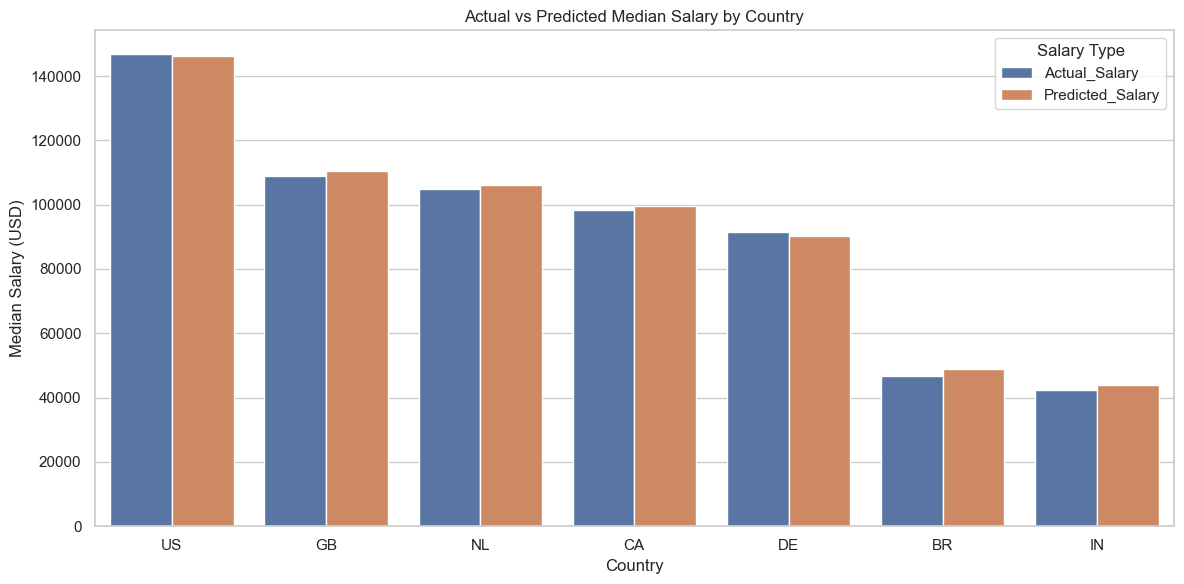

Model: CatBoost
MAE: 5767.18
RMSE: 7581.13
R2: 0.983

Visualization completed!


In [21]:
sns.set_theme(style="whitegrid")

actual = np.array(y_test)
predicted = np.array(best_predictions)

residuals = actual - predicted
absolute_errors = np.abs(residuals)


# 10.1 ACTUAL VS PREDICTED

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=actual,
    y=predicted,
    alpha=0.6
)

min_value = min(actual.min(), predicted.min())
max_value = max(actual.max(), predicted.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted Salaries")
plt.xlabel("Actual Salary (USD)")
plt.ylabel("Predicted Salary (USD)")
plt.legend()

plt.tight_layout()
plt.show()


# 10.2 RESIDUAL PLOT

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=predicted,
    y=residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=2
)

plt.title("Residual Plot")
plt.xlabel("Predicted Salary (USD)")
plt.ylabel("Residuals (USD)")

plt.tight_layout()
plt.show()


# 10.3 ERROR DISTRIBUTION

plt.figure(figsize=(10, 6))

sns.histplot(
    residuals,
    bins=30,
    kde=True
)

plt.axvline(
    x=0,
    linestyle="--",
    linewidth=2
)

plt.title("Distribution of Prediction Errors")
plt.xlabel("Prediction Error (USD)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


# 10.4 FEATURE IMPORTANCE

if best_model_name == "CatBoost":

    importance = best_model.feature_importances_

    feature_importance = pd.DataFrame({
        "Feature": catboost_features,
        "Importance": importance
    })

elif best_model_name in [
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting"
]:

    fitted_model = best_model.named_steps["model"]

    transformed_features = (
        best_model.named_steps["preprocessor"]
        .get_feature_names_out()
    )

    feature_importance = pd.DataFrame({
        "Feature": transformed_features,
        "Importance": fitted_model.feature_importances_
    })

else:

    feature_importance = None


if feature_importance is not None:

    feature_importance = feature_importance.sort_values(
        "Importance",
        ascending=False
    ).head(15)

    plt.figure(figsize=(10, 7))

    sns.barplot(
        data=feature_importance,
        x="Importance",
        y="Feature"
    )

    plt.title("Top 15 Feature Importances")
    plt.xlabel("Importance")
    plt.ylabel("Feature")

    plt.tight_layout()
    plt.show()


# 10.5 ACTUAL VS PREDICTED BY COUNTRY

country_plot_df = pd.DataFrame({
    "Country": sorted_df.loc[
        X_test.index, "country"
    ].values,
    "Actual": actual,
    "Predicted": predicted
})

country_comparison = (
    country_plot_df
    .groupby("Country")
    .agg(
        Actual_Salary=("Actual", "median"),
        Predicted_Salary=("Predicted", "median"),
        Postings=("Actual", "count")
    )
    .reset_index()
)

country_comparison = country_comparison.sort_values(
    "Actual_Salary",
    ascending=False
)

country_comparison = country_comparison[
    country_comparison["Postings"] >= 10
]

country_comparison_melted = country_comparison.melt(
    id_vars="Country",
    value_vars=["Actual_Salary", "Predicted_Salary"],
    var_name="Salary_Type",
    value_name="Salary"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=country_comparison_melted,
    x="Country",
    y="Salary",
    hue="Salary_Type"
)

plt.title("Actual vs Predicted Median Salary by Country")
plt.xlabel("Country")
plt.ylabel("Median Salary (USD)")
plt.legend(title="Salary Type")

plt.tight_layout()
plt.show()


# 10.6 VISUALIZATION SUMMARY

print("Model:", best_model_name)
print("MAE:", round(mean_absolute_error(actual, predicted), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(actual, predicted)), 2))
print("R2:", round(r2_score(actual, predicted), 4))

print("\nVisualization completed!")